# Assignment 3 - Bruno Cavagnaro

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore")
np.set_printoptions(precision=4, suppress=True)

## Problem 1(a) — First PC vs. first Fisher discriminant
The points of Figure 1 were **digitized approximately** by eye from the PDF (positions are accurate to about ±0.1), so the computed directions are close to, but not exactly, those of the original data.

* **PCA** ignores labels and maximizes projected variance, so the direction follows the long axis of the cloud: roughly the 45° diagonal.
* **Fisher LDA** maximizes $\frac{(w^\top(m_+-m_-))^2}{w^\top S_W w}$, giving $w \propto S_W^{-1}(m_+-m_-)$. Every class is stretched along the diagonal (large within-class variance there), while the circles sit *above-left* of the diamonds/squares. So LDA picks the direction roughly **perpendicular** to the PC, pointing toward the circles (upper-left).

PCA dir [0.727 0.686] angle 43.3
LDA dir [-0.667  0.745] angle 131.8
angle between 88.5


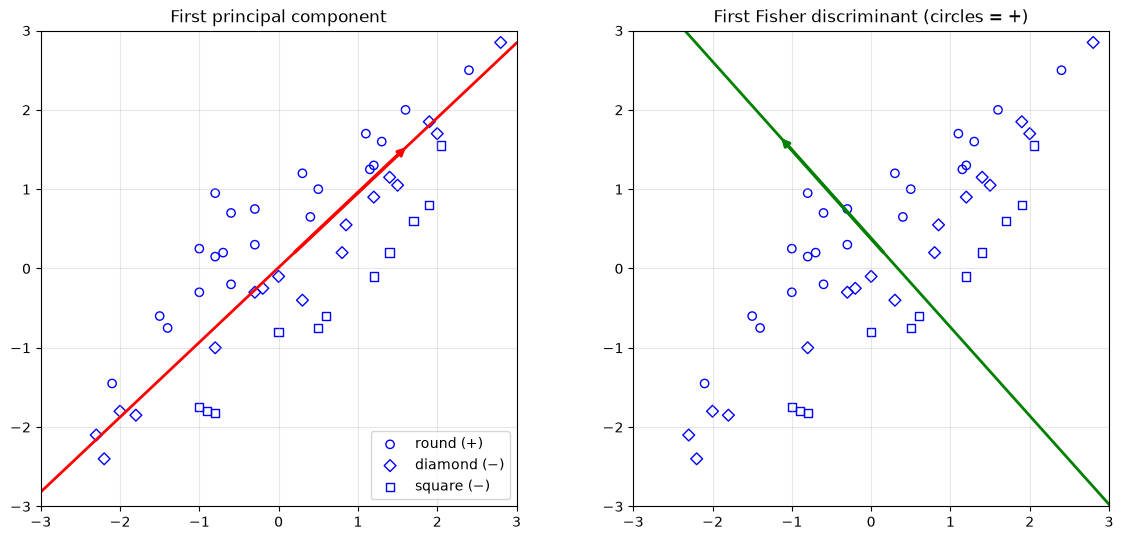

In [ ]:
C = np.array([(2.4,2.5),(1.6,2.0),(1.1,1.7),(1.3,1.6),(1.15,1.25),(1.2,1.3),(0.3,1.2),(0.5,1.0),(0.4,0.65), (-0.8,0.95),(-0.6,0.7),(-0.3,0.75),(-1.0,0.25),(-0.8,0.15),(-0.7,0.2),(-0.3,0.3),(-1.0,-0.3),
              (-0.6,-0.2),(-1.5,-0.6),(-1.4,-0.75),(-2.1,-1.45)])
D = np.array([(2.8,2.85),(1.9,1.85),(2.0,1.7),(1.4,1.15),(1.5,1.05),(1.2,0.9),(0.85,0.55),(0.8,0.2),(-0.3,-0.3),(-0.2,-0.25),(0.0,-0.1),(0.3,-0.4),(-0.8,-1.0),(-2.3,-2.1),(-2.0,-1.8),(-1.8,-1.85),(-2.2,-2.4)])
S = np.array([(2.05,1.55),(1.9,0.8),(1.7,0.6),(1.4,0.2),(1.2,-0.1),(0.6,-0.6),(0.5,-0.75),(0.0,-0.8),(-1.0,-1.75),(-0.9,-1.8),(-0.8,-1.82)])

X = np.vstack([C,D,S]); y = np.r_[np.ones(len(C)), np.zeros(len(D)+len(S))]
mu = X.mean(0)

# PCA
w_pca = np.linalg.eigh(np.cov(X.T))[1][:,-1]; w_pca *= np.sign(w_pca[0])

# Fisher LDA: w ∝ Sw^{-1}(m1-m0)
m1, m0 = X[y==1].mean(0), X[y==0].mean(0)
Sw = np.cov(X[y==1].T)*(sum(y==1)-1) + np.cov(X[y==0].T)*(sum(y==0)-1)
w_lda = np.linalg.solve(Sw, m1-m0); w_lda /= np.linalg.norm(w_lda)

ang = lambda w: np.degrees(np.arctan2(w[1],w[0]))

print("PCA dir", w_pca.round(3), "angle", ang(w_pca).round(1))
print("LDA dir", w_lda.round(3), "angle", ang(w_lda).round(1))
print("angle between", round(abs(ang(w_pca)-ang(w_lda)),1))

fig, ax = plt.subplots(1,2,figsize=(12,5.5))

for a,w,t,c in zip(ax,[w_pca,w_lda],["First principal component","First Fisher discriminant (circles = +)"],["red","green"]):
    a.scatter(*C.T,marker='o',facecolors='none',edgecolors='b',label='round (+)')
    a.scatter(*D.T,marker='D',facecolors='none',edgecolors='b',label='diamond (−)')
    a.scatter(*S.T,marker='s',facecolors='none',edgecolors='b',label='square (−)')
    a.axline(mu, mu+w, color=c, lw=2); a.annotate("",mu+2*w,mu,arrowprops=dict(arrowstyle="->",color=c,lw=2.5))
    a.set_xlim(-3,3); a.set_ylim(-3,3); a.set_aspect('equal'); a.set_title(t); a.grid(alpha=.3)
ax[0].legend(loc='lower right')

plt.tight_layout()
plt.show()

## Problem 1(b) — PCA on (−1,−1), (0,0), (1,1)

Mean is $(0,0)$. Scatter matrix $\sum x_i x_i^\top = \begin{pmatrix}2&2\\2&2\end{pmatrix}$, eigenvalues 4 and 0.

* First principal component: $v_1 = \left(\tfrac{1}{\sqrt2},\tfrac{1}{\sqrt2}\right)$ (sign is arbitrary).
* 1-d coordinates $z_i = v_1^\top x_i$: $\;-\sqrt2,\; 0,\; \sqrt2$.
* Variance of the projection: $\frac{2+0+2}{3} = \frac43$ (dividing by $n$; equals 2 if you use the unbiased $n-1$ version).
* Reconstruction $\hat x_i = z_i v_1$ gives back $(-1,-1),(0,0),(1,1)$ exactly, so the **reconstruction error is 0**: all points lie on the line spanned by $v_1$ (the second eigenvalue is 0).

In [3]:
P = np.array([[-1,-1],[0,0],[1,1]], float)
mu = P.mean(0); Pc = P - mu
vals, vecs = np.linalg.eigh(Pc.T @ Pc / len(P))
v1 = vecs[:, -1] * np.sign(vecs[0, -1])
z = Pc @ v1
R = np.outer(z, v1) + mu

print("eigenvalues:", vals)
print("first PC:", v1)
print("1-d coordinates:", z)
print("variance (1/n):", z.var(), "| variance (1/(n-1)):", z.var(ddof=1))
print("reconstruction:\n", R)
print("reconstruction error (sum of squares):", round(((P - R)**2).sum(), 12))

eigenvalues: [0.     1.3333]
first PC: [0.7071 0.7071]
1-d coordinates: [-1.4142  0.      1.4142]
variance (1/n): 1.333333333333333 | variance (1/(n-1)): 1.9999999999999996
reconstruction:
 [[-1. -1.]
 [ 0.  0.]
 [ 1.  1.]]
reconstruction error (sum of squares): 0.0


## Problem 2 — K-means on MNIST digits {0, 5, 8, 9}
Put **mnist_train.csv** (Kaggle version) in the working directory. The loader handles files with or without a header row.

In [4]:
df = pd.read_csv("mnist_train.csv", header=None)

if not str(df.iloc[0, 0]).isdigit():        # Kaggle file has a header row
    df = df.iloc[1:].astype(int)

df = df[df[0].isin([0, 5, 8, 9])]
y = df[0].values
X = df.iloc[:, 1:].values.astype(np.float32) / 255.0

print(X.shape, dict(zip(*np.unique(y, return_counts=True))))

def cluster_accuracy(y, lab):
    """Majority-takes-all accuracy as defined in the assignment."""
    return sum(np.bincount(y[lab == k]).max() for k in np.unique(lab)) / len(y)

def cluster_table(y, lab):
    t = pd.crosstab(pd.Series(lab, name="cluster"), pd.Series(y, name="true digit"))
    t["majority"] = t.idxmax(axis=1); t["cluster acc"] = (t.drop(columns="majority").max(1) / t.drop(columns="majority").sum(1)).round(3)
    return t

(23144, 784) {np.int64(0): np.int64(5923), np.int64(5): np.int64(5421), np.int64(8): np.int64(5851), np.int64(9): np.int64(5949)}


### 2(a) Baseline: plain K-means on raw pixels
K-means++ initialization, 20 restarts, keep the lowest inertia.

In [5]:
from sklearn.cluster import KMeans

km_raw = KMeans(n_clusters=4, n_init=20, random_state=0).fit(X)
lab_raw = km_raw.labels_

print("Raw-pixel K-means accuracy:", round(cluster_accuracy(y, lab_raw), 4))

cluster_table(y, lab_raw)

Raw-pixel K-means accuracy: 0.6277


true digit,0,5,8,9,majority,cluster acc
cluster,,,,,,
0,26,379,335,4354,9,0.855
1,596,2462,2500,134,8,0.439
2,4688,67,31,63,0,0.967
3,613,2513,2985,1398,8,0.398


Raw-pixel K-means reaches only about 63%: two clusters end up as "8"-like shapes and **no cluster captures the 5s**, which get spread across the 8/9/0 clusters. Euclidean distance on 784 pixels is dominated by stroke thickness and slant rather than digit identity.

### 2(a) Improved pipeline: PCA(50) → UMAP(10-d) → K-means

The clustering step is still K-means with K = 4; only the feature space changes.
1. **PCA to 50 dims** removes pixel noise and speeds things up.
2. **UMAP** builds a k-nearest-neighbour graph and embeds it so that points on the same digit manifold end up close together. This turns the curved, elongated digit manifolds into compact, roughly spherical blobs, which is exactly the shape K-means assumes.
3. **K-means (K = 4, 20 restarts)** on the 10-d embedding.

In [6]:
from sklearn.decomposition import PCA
import umap

Z50 = PCA(n_components=50, random_state=0).fit_transform(X)
E = umap.UMAP(n_neighbors=15, min_dist=0.0, n_components=10, random_state=0).fit_transform(Z50)
km = KMeans(n_clusters=4, n_init=20, random_state=0).fit(E)
lab = km.labels_

print("PCA+UMAP+K-means accuracy:", round(cluster_accuracy(y, lab), 4))
cluster_table(y, lab)

PCA+UMAP+K-means accuracy: 0.9839


true digit,0,5,8,9,majority,cluster acc
cluster,,,,,,
0,5,20,5695,92,8,0.980
1,5907,11,11,18,0,0.993
2,4,38,48,5818,9,0.985
3,7,5352,97,21,5,0.977


**Drawing the centroids.** The K-means centroids of the improved model live in UMAP space, so to display them as images I take, for each cluster, the mean image of its members (this is exactly what a K-means centroid is in pixel space, given the cluster assignment). The raw-pixel K-means centroids are shown below for comparison.

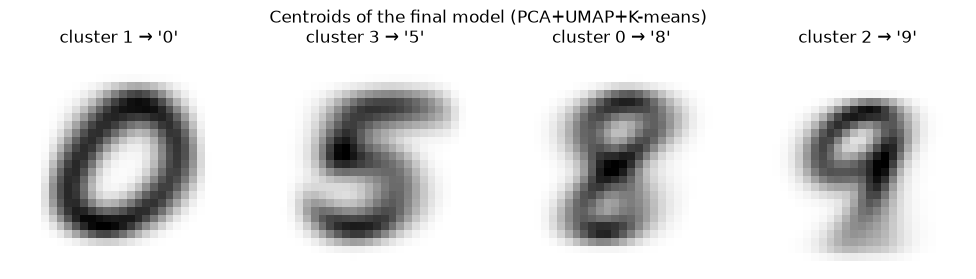

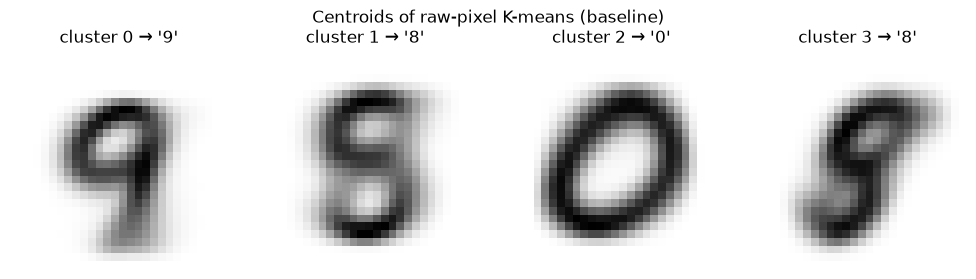

In [7]:
def show_centroids(imgs, labels_list, title):
    fig, ax = plt.subplots(1, 4, figsize=(10, 2.8))

    for a, img, t in zip(ax, imgs, labels_list):
        a.imshow(img.reshape(28, 28), cmap="gray_r"); a.set_title(t); a.axis("off")

    fig.suptitle(title); plt.tight_layout(); plt.show()


def majority(y, lab, k): 
    return np.bincount(y[lab == k]).argmax()

order = np.argsort([majority(y, lab, k) for k in range(4)])
cents = [X[lab == k].mean(0) for k in order]

show_centroids(cents, [f"cluster {k} → '{majority(y, lab, k)}'" for k in order],
               "Centroids of the final model (PCA+UMAP+K-means)")

show_centroids(km_raw.cluster_centers_, [f"cluster {k} → '{majority(y, lab_raw, k)}'" for k in range(4)],
               "Centroids of raw-pixel K-means (baseline)")

### 2(b) Performance analysis
Accuracy uses the majority-takes-all definition: for each cluster count the most frequent true label; sum those counts over clusters and divide by the number of images. The comparison below includes an intermediate variant (whitened PCA) and checks stability across UMAP seeds.

In [8]:
rows = [("Raw pixels", cluster_accuracy(y, lab_raw))]
Zw = PCA(n_components=20, whiten=True, random_state=0).fit_transform(X)

rows.append(("Whitened PCA(20)", cluster_accuracy(y, KMeans(4, n_init=20, random_state=0).fit_predict(Zw))))
rows.append(("PCA(50)+UMAP(10), seed 0", cluster_accuracy(y, lab)))

for s in [1, 2]:
    Es = umap.UMAP(n_neighbors=15, min_dist=0.0, n_components=10, random_state=s).fit_transform(Z50)
    rows.append((f"PCA(50)+UMAP(10), seed {s}", cluster_accuracy(y, KMeans(4, n_init=20, random_state=0).fit_predict(Es))))
    
pd.DataFrame(rows, columns=["method", "accuracy"]).round(4)

,method,accuracy
0,Raw pixels,0.6277
1,Whitened PCA(20),0.7760
2,"PCA(50)+UMAP(10), seed 0",0.9839
3,"PCA(50)+UMAP(10), seed 1",0.9836
4,"PCA(50)+UMAP(10), seed 2",0.9835


### 2(c) Selecting K
We do not use the labels. For K = 2,…,10 on the same embedding we compute:
* **Elbow (inertia / within-cluster SS)**: pick the K after which adding clusters stops giving large drops.
* **Silhouette score** (higher is better): how much closer each point is to its own cluster than to the nearest other cluster. Computed on a random subsample of 5,000 points for speed.
* **Calinski–Harabasz index** (higher is better): ratio of between- to within-cluster dispersion.

Other valid options: the gap statistic, or fitting Gaussian mixtures and choosing K by BIC.

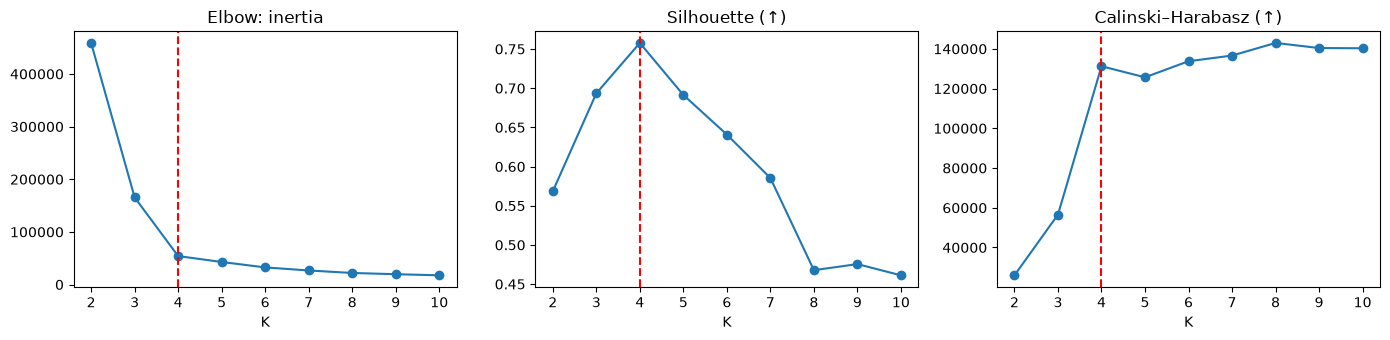

K by silhouette: 4 | K by Calinski-Harabasz: 8


In [9]:
from sklearn.metrics import silhouette_score, calinski_harabasz_score
Ks = range(2, 11); inertia, sil, ch = [], [], []

for k in Ks:
    m = KMeans(n_clusters=k, n_init=10, random_state=0).fit(E)
    inertia.append(m.inertia_)
    sil.append(silhouette_score(E, m.labels_, sample_size=5000, random_state=0))
    ch.append(calinski_harabasz_score(E, m.labels_))

fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))

for a, v, t in zip(ax, [inertia, sil, ch], ["Elbow: inertia", "Silhouette (↑)", "Calinski–Harabasz (↑)"]):
    a.plot(list(Ks), v, "o-"); a.axvline(4, color="r", ls="--"); a.set_title(t); a.set_xlabel("K")

plt.tight_layout()
plt.show()

print("K by silhouette:", list(Ks)[int(np.argmax(sil))], "| K by Calinski-Harabasz:", list(Ks)[int(np.argmax(ch))])

**Conclusion for K.** The elbow is sharp at K = 4 (inertia falls from about 460k → 167k → 55k, then flattens), and the silhouette has a clear maximum at **K = 4** (≈ 0.76). Calinski–Harabasz jumps up to K = 4 and then only creeps upward (its maximum at 8 is a marginal gain, because UMAP creates small sub-clusters within each digit and CH is known to favour larger K in that case). Combining the criteria, we choose **K = 4**, which matches the true number of digits.

## Problem 3 — Monte Carlo sampling from the 8-Gaussian mixture
**Method: rejection sampling** using only the pdf formula $f(x)=\sum_k p_k\,\mathcal N(x\mid\mu_k,\Sigma_k)$ as a black box.

* Proposal $g$: uniform on the box $[-2-8\sigma,\;2+8\sigma]^2$ (the mass outside is negligible, below $10^{-14}$).
* Envelope: $f(x)\le f_{\max}$, where $f_{\max}=\max_k f(\mu_k)\approx \frac18\cdot\frac{1}{2\pi\sigma^2}\approx 49.7$ (the modes are far apart, so overlap is nil).
* Draw $x\sim g$, $u\sim U(0,f_{\max})$; accept $x$ if $u<f(x)$. Accepted points are **exact** i.i.d. draws from $f$.
* Acceptance rate $=1/(\text{area}\cdot f_{\max})\approx 0.108\%$. Small, but fully vectorized, so about 750k proposals take well under a second.

Why not MCMC? With $\sigma=0.02$ and modes 1.5 apart, a Metropolis random walk would almost never jump between modes, so the chain would get stuck in one or two components. Rejection sampling avoids that entirely.

**Variance reduction (Quasi-Monte Carlo):** replacing the pseudo-random $(x,u)$ triples with a scrambled **Sobol** sequence spreads proposals more evenly, so the number of accepted points per mode is much closer to 100 each. The "real" sample has exactly 100 per mode, so this balance strongly reduces the MMD.

In [10]:
import numpy as np
from scipy.stats import qmc

K, R, SD = 8, 2.0, 0.02
MU = np.array([[R*np.cos(2*np.pi*k/K), R*np.sin(2*np.pi*k/K)] for k in range(K)])

def pdf(x):  # mixture pdf formula only
    d2 = ((x[:,None,:]-MU[None])**2).sum(-1)
    return (np.exp(-d2/(2*SD**2))/(2*np.pi*SD**2)).mean(1)

FMAX = pdf(MU).max()*1.0001  # max of pdf (at the means) -> envelope constant
LO, HI = -R-8*SD, R+8*SD

def rejection(n, rng, qmc_seed=None):
    out=[]; tried=0
    sob = qmc.Sobol(3, scramble=True, seed=qmc_seed) if qmc_seed is not None else None
    while sum(len(o) for o in out)<n:
        U = sob.random(2**20) if sob else rng.random((10**6,3))
        x = LO+(HI-LO)*U[:,:2]; u = U[:,2]*FMAX
        out.append(x[u<pdf(x)]); tried+=len(U)
    S = np.vstack(out)
    return S[:n], len(S)/tried

def mmd(x, y, kernel):  # numpy port of the Kaggle notebook (biased estimator)
    dxx=((x[:,None]-x[None])**2).sum(-1); dyy=((y[:,None]-y[None])**2).sum(-1); dxy=((x[:,None]-y[None])**2).sum(-1)
    XX=np.zeros_like(dxx); YY=np.zeros_like(dyy); XY=np.zeros_like(dxy)
    if kernel=="multiscale":
        for a in [0.2,0.5,0.9,1.3]:
            XX+=a**2/(a**2+dxx); YY+=a**2/(a**2+dyy); XY+=a**2/(a**2+dxy)
    else:
        for a in [10,15,20,50]:
            XX+=np.exp(-0.5*dxx/a); YY+=np.exp(-0.5*dyy/a); XY+=np.exp(-0.5*dxy/a)
    return XX.mean()+YY.mean()-2*XY.mean()

def real(rng): 
    return np.vstack([rng.normal(m, SD, (100,2)) for m in MU])

acceptance rate: 0.00110 (theory 0.00108)
points per mode  MC : [106 102 104  78  91 105 108 106]
points per mode  QMC: [100 103  98 105 103  97  99  95]


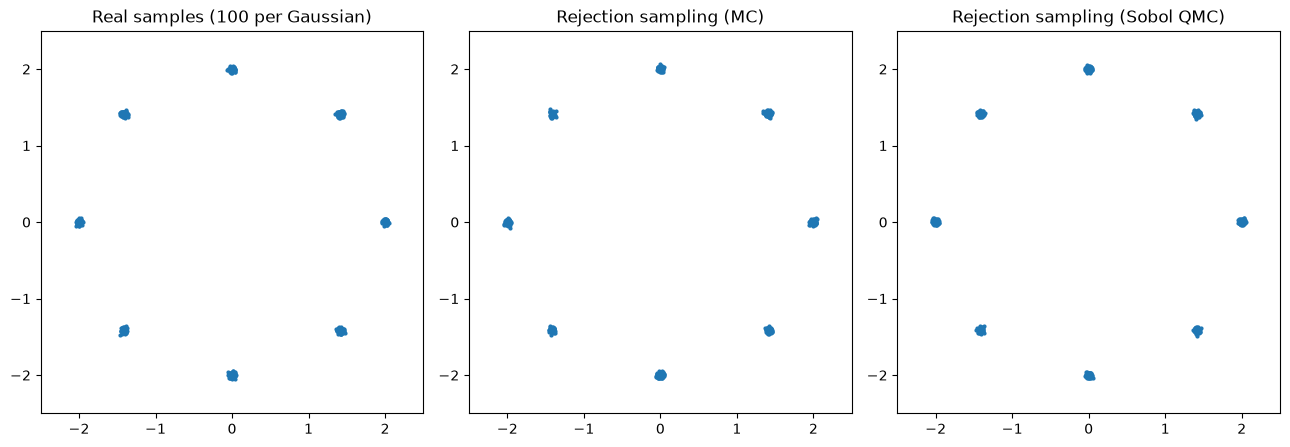

In [11]:
rng = np.random.default_rng(0)
S_mc, acc_mc = rejection(800, rng)
S_qmc, acc_qmc = rejection(800, rng, qmc_seed=1)

print(f"acceptance rate: {acc_mc:.5f} (theory {1/((HI-LO)**2*FMAX):.5f})")

mode_of = lambda S: np.bincount(np.argmin(((S[:, None] - MU)**2).sum(-1), 1), minlength=8)

print("points per mode  MC :", mode_of(S_mc))
print("points per mode  QMC:", mode_of(S_qmc))

Real = real(np.random.default_rng(123))
fig, ax = plt.subplots(1, 3, figsize=(13, 4.3))

for a, S, t in zip(ax, [Real, S_mc, S_qmc], ["Real samples (100 per Gaussian)", "Rejection sampling (MC)", "Rejection sampling (Sobol QMC)"]):
    a.scatter(*S.T, s=4); a.set_aspect("equal"); a.set_title(t); a.set_xlim(-2.5, 2.5); a.set_ylim(-2.5, 2.5)

plt.tight_layout()
plt.show()

**MMD evaluation.** **mmd()** is a NumPy port of the Kaggle notebook's function (biased estimator, same **multiscale** and **rbf** bandwidths). Since the "real" sample is itself random, I average over 20 independent real samples and also over several sampler seeds. The *real vs. real* line is the noise floor: what two exact samples of the same distribution score.

In [12]:
res = []
for name, fn in [("Rejection MC", lambda s: rejection(800, np.random.default_rng(s))[0]),
                 ("Rejection QMC (Sobol)", lambda s: rejection(800, None, qmc_seed=s)[0]),
                 ("Real vs real (floor)", lambda s: real(np.random.default_rng(1000 + s)))]:
    
    for kern in ["multiscale", "rbf"]:
        v = [mmd(fn(s), real(np.random.default_rng(s + 50)), kern) for s in range(10)]
        res.append((name, kern, np.mean(v), np.std(v)))
        
pd.DataFrame(res, columns=["sampler", "kernel", "mean MMD", "std"])

,sampler,kernel,mean MMD,std
0,Rejection MC,multiscale,3.359203e-03,1.559132e-03
1,Rejection MC,rbf,1.071125e-03,6.506382e-04
2,Rejection QMC (Sobol),multiscale,7.259377e-04,2.857030e-04
3,Rejection QMC (Sobol),rbf,1.845912e-04,1.798185e-04
4,Real vs real (floor),multiscale,1.314670e-04,3.731430e-05
5,Real vs real (floor),rbf,6.763434e-07,4.774763e-07


For the submission, report the MMD of the specific 800 samples you submit (the **S_qmc** sample above) against one set of real samples:

In [13]:
print("Submitted sample (QMC rejection) — MMD multiscale:", mmd(S_qmc, Real, "multiscale"))
print("Submitted sample (QMC rejection) — MMD rbf       :", mmd(S_qmc, Real, "rbf"))
np.savetxt("gmm_samples_800.csv", S_qmc, delimiter=",", header="x,y", comments="")

Submitted sample (QMC rejection) — MMD multiscale: 0.0005435251679952735
Submitted sample (QMC rejection) — MMD rbf       : 0.00017386649741979454


**Conclusion for Problem 3.** Rejection sampling produces exact draws using only the pdf. With pseudo-random proposals the MMD (multiscale) is about 3×10⁻³, driven mostly by random imbalance in how many points land in each mode. Using a Sobol QMC sequence for the proposals brings it down to about 5–7×10⁻⁴, within a small factor of the real-vs-real floor (about 1.3×10⁻⁴).